In [1]:
import pandas as pd

from fowt_ml.datasets import get_data, fix_column_names
import numpy as np


import sys
sys.path.append("../")

from utils import plot_forces, compute_mi_scores, compare_forces, correct_force

### Load the data in a dataframe

In [2]:
# create a data config
# data_ids = ["exp1644", "exp1646", "exp1648", "exp1651", "exp1653", "exp1656"]
data_id = "exp1656" 
cfg = {
    data_id: {
        "path_file": f"./hybridlabs/data_x_wp2_202512/dataB/decay_cl/{data_id}.mat",
        "aux_data": {"wind_speed": 0.0},      
  }
}  # closed-loop, surge case, no wind, no-rotation

In [3]:
df = get_data(data_id=data_id, config=cfg)
df.index = pd.to_timedelta(df.index*1e-3, unit='s')  # set time index 

In [4]:
print(len(df), df.columns)

43601 Index(['time', 'acc_calc6[0]', 'acc_calc6[1]', 'acc_calc6[2]', 'acc_calc6[3]',
       'acc_calc6[4]', 'acc_calc6[5]', 'acc_tb_meas3[0]', 'acc_tb_meas3[1]',
       'acc_tb_meas3[2]',
       ...
       'spd_rot_cmd', 'time_wave_precalc', 'tq_mot_act', 'trig_Hex_in',
       'trig_PIV_in', 'trig_PIV_out', 'wtm2_spd_rot_act', 'wtm2_spd_rot_cmd',
       'wtm2_tq_mot_act', 'wind_speed'],
      dtype='object', length=146)


#### Inspecting the data

In no-wind (wind speed is zero) and no-rotation (rotational speed is zero) conditions,
the measured forces are considered to be of inertial and gravitational origin only 
i.e. `F_meas = F_in + F_grav` and the aerodynamic forces (F_aero) are considered to be negligible (~0).
In physics-based method, `F_corr = F_in + F_grav` is calculated using acceleration. Then, `Faero_est = F_meas − F_corr`.

In [12]:
# all in rotating frame
acc_meas_tb = [
    'acc_tb_meas3[0]',
    'acc_tb_meas3[1]',
    'acc_tb_meas3[2]',
]
acc_meas_tt = [
    'acc_tt_meas3[0]',
    'acc_tt_meas3[1]',
    'acc_tt_meas3[2]',
]

meas = [
     'force_tt_meas6[0]',
     'force_tt_meas6[1]',
     'force_tt_meas6[2]',
     'force_tt_meas6[3]',
     'force_tt_meas6[4]',
     'force_tt_meas6[5]',
 ]

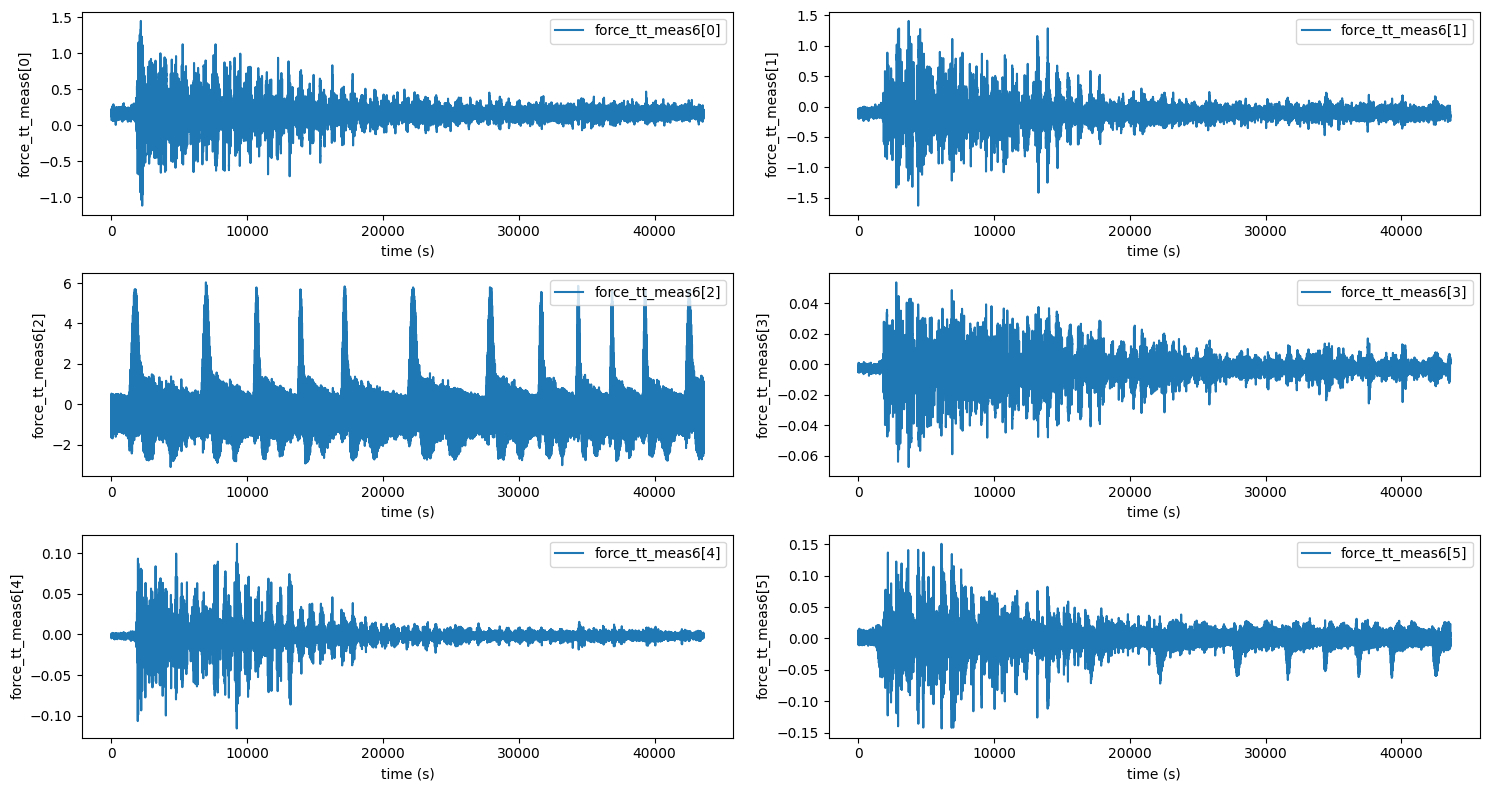

In [14]:
plot_forces(df[meas])

#### Defining targets and features

We want to estimate the measured rotor forces from the measured acceleration and/or position
(POS). This would be equivalent to F_corr. The variables are:

- acceleration in xyz-direction measured at nacelle (acc_tt) and at tower base (acc_tb)
- rotor force in xyz-direction measured under the nacelle (force_tt)

We can computes mutual information scores between them.

In [17]:
# check the mutual info between targets and features
targets = [
    'force_tt_meas6[0]',
    'force_tt_meas6[1]',
    'force_tt_meas6[2]',
    'force_tt_meas6[3]',
    'force_tt_meas6[4]',
    'force_tt_meas6[5]',
]

predictors = [
    'acc_tb_meas3[0]',
    'acc_tb_meas3[1]',
    'acc_tb_meas3[2]',
    'acc_tt_meas3[0]',
    'acc_tt_meas3[1]',
    'acc_tt_meas3[2]',
    'pos_act6[0]',
    'pos_act6[1]',
    'pos_act6[2]',
    'pos_act6[3]',
    'pos_act6[4]',
    'pos_act6[5]',
]

mi_scores = compute_mi_scores(df, targets, predictors)

In [18]:
print(mi_scores)

                 force_tt_meas6[0]  force_tt_meas6[1]  force_tt_meas6[2]  \
acc_tb_meas3[0]           0.124166           0.099600           0.026319   
acc_tb_meas3[1]           0.083817           0.121218           0.030282   
acc_tb_meas3[2]           0.058660           0.044341           0.014099   
acc_tt_meas3[0]           0.816135           0.128845           0.049694   
acc_tt_meas3[1]           0.105878           0.642355           0.034869   
acc_tt_meas3[2]           0.049444           0.046129           0.027980   
pos_act6[0]               0.108827           0.105966           0.020322   
pos_act6[1]               0.125761           0.128710           0.041511   
pos_act6[2]               0.024945           0.028049           0.027975   
pos_act6[3]               0.045204           0.057135           0.016057   
pos_act6[4]               0.033113           0.027533           0.017696   
pos_act6[5]               0.250041           0.242277           0.099027   

           